# DATA 266 HW4.5 — GPU Assignment II: Training Throughput and Memory Engineering

Kavan Siddesh Kumar · SID4 9486

This notebook takes the BERT fine-tune from `HW4a_BERT_vLLM.ipynb` and measures how its throughput and memory change on real hardware:

- **Part A:** batch scaling up to the memory wall.
- **Part B:** four memory techniques, each tested on its own, plus a best combination.
- **Part C:** two-GPU DDP. Skipped, since the instructor made it optional.
- **Part D:** the vLLM serving benchmark rerun, plus KV-cache memory against context length.
- **Part E:** GPU-hour estimate and summary.

**Hardware.** The lab run uses one NVIDIA RTX 4090. The assignment asks for comparisons "on each card", but only one card was available to me. Every two-card comparison is therefore marked as not run instead of being filled in.

**Run order.** Run `HW4a_BERT_vLLM.ipynb` first in the same `RUN_MODE`. This notebook loads its config, split, prompts and baseline numbers from `results/<mode>/`, and checks that the data and split are identical.

`RUN_MODE = "smoke"` is a tiny local CPU check. Its numbers are never used as results. `RUN_MODE = "gpu"` is the real RTX 4090 run.

## 2. Personal parameters and reproducibility

In [1]:
SID4 = 9486
SEED = 9486
SLICE = 486
HP_ID = 0
CLS_A = 6
CLS_B = 0

import os, torch
# "smoke" = local CPU check, "gpu" = RTX 4090 run. If RUN_MODE is not set in the shell
# (e.g. "Run All" in VS Code or Jupyter), it is "gpu" when a CUDA GPU is visible, else "smoke".
RUN_MODE = os.environ.get("RUN_MODE") or ("gpu" if torch.cuda.is_available() else "smoke")
assert RUN_MODE in ("smoke", "gpu"), RUN_MODE
print(f"SID4={SID4} SEED={SEED} SLICE={SLICE} HP_ID={HP_ID} CLS_A={CLS_A} CLS_B={CLS_B} RUN_MODE={RUN_MODE}")

SID4=9486 SEED=9486 SLICE=486 HP_ID=0 CLS_A=6 CLS_B=0 RUN_MODE=smoke


In [2]:
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

import random
import numpy as np
import torch

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True, warn_only=True)

SEED is used everywhere HW4.a used it: the split, the training data order, and right before every BERT model is created. Every configuration therefore starts from the same classifier-head weights and sees the training batches in the same order. Deterministic algorithms stay on for all training runs, so the comparison between techniques is fair, though this can cost a little throughput compared with the fastest nondeterministic kernels. Serving latencies still vary a little from run to run.

## 3. Environment and hardware inspection

In [3]:
import sys, json, time, math, platform, subprocess, datetime, traceback, gc, hashlib, contextlib
from importlib import metadata
from pathlib import Path

HW_DIR = Path.cwd()
RESULTS_DIR = HW_DIR / "results" / RUN_MODE
FIG_DIR = HW_DIR / "figures" / RUN_MODE
PROV_DIR = HW_DIR / "provenance"
for d in (RESULTS_DIR, FIG_DIR, PROV_DIR):
    d.mkdir(parents=True, exist_ok=True)

CUDA = torch.cuda.is_available()
if RUN_MODE == "gpu" and not CUDA:
    raise RuntimeError("RUN_MODE is 'gpu' but torch.cuda.is_available() is False.")
DEVICE = torch.device("cuda" if CUDA else "cpu")
GPU_NAME = torch.cuda.get_device_name(0) if CUDA else "none (CPU only)"
if RUN_MODE == "smoke":
    RUN_LABEL = "[SMOKE TEST]"
elif "4090" in GPU_NAME:
    RUN_LABEL = "[RTX 4090 RUN]"
else:
    RUN_LABEL = f"[GPU RUN — {GPU_NAME}]"

LOG_FILE = RESULTS_DIR / "run_log_hw45.txt"

def now_utc():
    return datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ")

def log(msg):
    line = f"{now_utc()} {RUN_LABEL} {msg}"
    print(line)
    with open(LOG_FILE, "a") as f:
        f.write(line + "\n")

def log_error(context, exc):
    log(f"[ERROR] {context}: {type(exc).__name__}: {exc}")
    with open(LOG_FILE, "a") as f:
        f.write(traceback.format_exc() + "\n")

def pkg_version(name):
    try:
        return metadata.version(name)
    except metadata.PackageNotFoundError:
        return "not installed"

def run_cmd(cmd):
    try:
        return subprocess.run(cmd, capture_output=True, text=True, timeout=60).stdout.strip()
    except (FileNotFoundError, subprocess.TimeoutExpired) as e:
        return f"unavailable ({type(e).__name__})"

ENV = {
    "notebook": "HW4.5_Throughput_Memory.ipynb",
    "run_mode": RUN_MODE,
    "run_label": RUN_LABEL,
    "start_utc": now_utc(),
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "torch": torch.__version__,
    "torch_cuda": torch.version.cuda,
    "cudnn": torch.backends.cudnn.version() if CUDA else None,
    "transformers": pkg_version("transformers"),
    "datasets": pkg_version("datasets"),
    "bitsandbytes": pkg_version("bitsandbytes"),
    "vllm": pkg_version("vllm"),
    "gpu_count": torch.cuda.device_count(),
    "gpus": [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())],
    "gpu_name": GPU_NAME,
    "gpu_vram_gb": round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2) if CUDA else None,
    "bf16_supported": torch.cuda.is_bf16_supported() if CUDA else None,
    "nvidia_smi_L": run_cmd(["nvidia-smi", "-L"]) if CUDA else "not run (no CUDA)",
}
if CUDA:
    stamp = ENV["start_utc"].replace(":", "")
    (PROV_DIR / f"nvidia_smi_q_hw45_{stamp}.txt").write_text(run_cmd(["nvidia-smi", "-q"]))
    (PROV_DIR / f"nvidia_smi_L_hw45_{stamp}.txt").write_text(ENV["nvidia_smi_L"] + "\n")

with open(LOG_FILE, "a") as f:
    f.write("\n" + "=" * 70 + "\n")
log("HW4.5 notebook started")
for k, v in ENV.items():
    print(f"{k:>14}: {v}")
_ = (RESULTS_DIR / "env_hw45.json").write_text(json.dumps(ENV, indent=2))

2026-10-27T00:22:00Z [SMOKE TEST] HW4.5 notebook started
      notebook: HW4.5_Throughput_Memory.ipynb
      run_mode: smoke
     run_label: [SMOKE TEST]
     start_utc: 2026-10-27T00:22:00Z
        python: 3.13.9
      platform: macOS-14.1.2-arm64-arm-64bit-Mach-O
         torch: 2.14.0
    torch_cuda: None
         cudnn: None
  transformers: 5.21.0
      datasets: 5.1.0
  bitsandbytes: not installed
          vllm: not installed
     gpu_count: 0
          gpus: []
      gpu_name: none (CPU only)
   gpu_vram_gb: None
bf16_supported: None
  nvidia_smi_L: not run (no CUDA)


## 4. Imports and helper functions

The helpers below only implement the mechanics: building the model, one optimizer step, a full fine-tune, a throughput epoch and a max-batch probe. Every experimental choice (batch sizes, which technique is on, step counts) is passed in explicitly from the configuration or the experiment cells.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
from transformers import (BertTokenizer, BertForSequenceClassification, get_linear_schedule_with_warmup,
                          AutoTokenizer, AutoModelForCausalLM, pipeline)
from torch.utils.data import TensorDataset, DataLoader, RandomSampler, SequentialSampler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

GB = 1024 ** 3   # memory is reported in GiB (1024^3 bytes), written as GB in the tables

def sync():
    if CUDA:
        torch.cuda.synchronize()

def reset_peak():
    if CUDA:
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()

def peak_memory_gb():
    if CUDA:
        return torch.cuda.max_memory_allocated() / GB, torch.cuda.max_memory_reserved() / GB
    return float("nan"), float("nan")

def free_memory():
    gc.collect()
    if CUDA:
        torch.cuda.empty_cache()

def short_error(e):
    return f"{type(e).__name__}: {str(e).strip().splitlines()[0][:200]}"

def md_table(frame, floatfmt="{:.3f}"):
    cols = list(frame.columns)
    lines = ["| " + " | ".join(map(str, cols)) + " |", "| " + " | ".join("---" for _ in cols) + " |"]
    for _, r in frame.iterrows():
        lines.append("| " + " | ".join(floatfmt.format(v) if isinstance(v, float) else str(v) for v in r) + " |")
    return "\n".join(lines)

W1026 17:22:03.989000 29371 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


In [5]:
def make_model(grad_ckpt=False, **config_overrides):
    set_seed(SEED)   # same classifier-head init for every configuration, as in HW4.a
    model = BertForSequenceClassification.from_pretrained(
        BERT_MODEL, revision=BERT_REVISION, num_labels=len(LABEL_NAMES),
        id2label=dict(enumerate(LABEL_NAMES)), label2id={n: i for i, n in enumerate(LABEL_NAMES)}, **config_overrides)
    if grad_ckpt:
        model.gradient_checkpointing_enable()
    return model.to(DEVICE)

def make_optimizer(model, optim_8bit=False):
    if optim_8bit:
        import bitsandbytes as bnb
        return bnb.optim.AdamW8bit(model.parameters(), lr=LR, eps=ADAM_EPS, weight_decay=WEIGHT_DECAY)
    return torch.optim.AdamW(model.parameters(), lr=LR, eps=ADAM_EPS, weight_decay=WEIGHT_DECAY)

def autocast_ctx(amp):
    return torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE) if amp else contextlib.nullcontext()

def make_train_loader(batch_size):
    # same sampler and generator seed as the HW4.a train loader
    return DataLoader(train_ds, sampler=RandomSampler(train_ds, generator=torch.Generator().manual_seed(SEED)),
                      batch_size=batch_size)

def train_step(model, optimizer, scheduler, micro_batches, amp):
    """One optimizer step over one or more micro-batches. Each micro-batch loss is weighted by its share of
    the samples, so accumulated gradients equal the gradient of the mean loss over the whole effective batch.
    With a single micro-batch this is exactly the HW4.a step."""
    optimizer.zero_grad(set_to_none=True)
    total = sum(len(mb[2]) for mb in micro_batches)
    loss_sum = 0.0
    for ids, mask, y in micro_batches:
        ids, mask, y = ids.to(DEVICE), mask.to(DEVICE), y.to(DEVICE)
        with autocast_ctx(amp):
            out = model(input_ids=ids, attention_mask=mask, labels=y)
        (out.loss * (len(y) / total)).backward()
        loss_sum += out.loss.item() * len(y)
    torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
    optimizer.step()
    scheduler.step()
    return loss_sum, total

def evaluate(model, loader, amp=False):
    model.eval()
    total_loss, preds, labels = 0.0, [], []
    with torch.no_grad():
        for ids, mask, y in loader:
            ids, mask, y = ids.to(DEVICE), mask.to(DEVICE), y.to(DEVICE)
            with autocast_ctx(amp):
                out = model(input_ids=ids, attention_mask=mask, labels=y)
            total_loss += out.loss.float().item() * len(y)
            preds.append(out.logits.float().argmax(-1).cpu()); labels.append(y.cpu())
    preds, labels = torch.cat(preds).numpy(), torch.cat(labels).numpy()
    assert len(preds) == len(labels)
    return total_loss / len(labels), accuracy_score(labels, preds)

In [6]:
def run_training(cfg, epochs):
    """Full fine-tune with one configuration. Same data, split, LR schedule, epochs and evaluation as HW4.a:
    validation after every epoch, best epoch by validation loss, test accuracy from the best epoch's weights."""
    physical, accum = cfg["physical_batch"], cfg["accum_steps"]
    model = make_model(cfg["grad_ckpt"])
    optimizer = make_optimizer(model, cfg["optim_8bit"])
    loader = make_train_loader(physical)
    steps_per_epoch = math.ceil(len(loader) / accum)
    scheduler = get_linear_schedule_with_warmup(optimizer, WARMUP_STEPS, steps_per_epoch * epochs)
    history, best_loss, best_epoch, best_state = [], float("inf"), None, None
    opt_steps = 0
    reset_peak()
    run_start = time.perf_counter()
    for epoch in range(1, epochs + 1):
        model.train()
        loss_sum, n_seen, group = 0.0, 0, []
        sync(); t0 = time.perf_counter()
        for batch in loader:
            group.append(batch)
            if len(group) == accum:
                l, n = train_step(model, optimizer, scheduler, group, cfg["amp"])
                loss_sum += l; n_seen += n; opt_steps += 1; group = []
        if group:
            l, n = train_step(model, optimizer, scheduler, group, cfg["amp"])
            loss_sum += l; n_seen += n; opt_steps += 1
        sync(); ep_s = time.perf_counter() - t0
        val_loss, val_acc = evaluate(model, val_loader, cfg["amp"])
        history.append({"config": cfg["name"], "epoch": epoch, "train_loss": loss_sum / n_seen, "val_loss": val_loss,
                        "val_acc": val_acc, "epoch_train_s": ep_s})
        if val_loss < best_loss:
            best_loss, best_epoch = val_loss, epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    sync()
    wall_s = time.perf_counter() - run_start
    alloc, reserved = peak_memory_gb()
    model.load_state_dict(best_state)
    test_loss, test_acc = evaluate(model, test_loader, cfg["amp"])
    train_s = sum(h["epoch_train_s"] for h in history)
    del model, optimizer, scheduler, best_state
    return {"physical_batch": physical, "accum_steps": accum, "effective_batch": physical * accum,
            "optimizer_steps": opt_steps, "train_time_s": train_s, "mean_epoch_s": train_s / epochs,
            "wall_time_incl_eval_s": wall_s, "samples_per_s": len(train_ds) * epochs / train_s,
            "peak_alloc_gb": alloc, "peak_reserved_gb": reserved, "final_val_acc": history[-1]["val_acc"],
            "best_epoch": best_epoch, "test_acc": test_acc}, history

def measure_epoch_throughput(batch_size, warmup_steps, cfg):
    """Part A: a few untimed warm-up steps, then one timed epoch over the full training split."""
    model = make_model(cfg["grad_ckpt"])
    optimizer = make_optimizer(model, cfg["optim_8bit"])
    loader = make_train_loader(batch_size)
    scheduler = get_linear_schedule_with_warmup(optimizer, WARMUP_STEPS, len(loader) * EPOCHS)
    model.train()
    warm = iter(loader)
    for _ in range(min(warmup_steps, len(loader))):
        train_step(model, optimizer, scheduler, [next(warm)], cfg["amp"])
    reset_peak()   # peak is measured after warm-up, during the timed epoch
    sync(); t0 = time.perf_counter()
    steps = 0
    for batch in loader:
        train_step(model, optimizer, scheduler, [batch], cfg["amp"])
        steps += 1
    sync(); epoch_s = time.perf_counter() - t0
    alloc, reserved = peak_memory_gb()
    del model, optimizer, scheduler
    return {"epoch_s": epoch_s, "optimizer_steps": steps, "samples_per_s": len(train_ds) / epoch_s,
            "peak_alloc_gb": alloc, "peak_reserved_gb": reserved}

def probe_step(cfg, batch_size, steps):
    """Part B max-batch probe: a few real training steps on batches of the given physical size
    (sampled with replacement so sizes above the train split still work)."""
    model = make_model(cfg["grad_ckpt"])
    optimizer = make_optimizer(model, cfg["optim_8bit"])
    scheduler = get_linear_schedule_with_warmup(optimizer, 0, 1000)
    model.train()
    g = torch.Generator().manual_seed(SEED)
    for _ in range(steps):
        micro = []
        for _ in range(cfg["accum_steps"]):
            idx = torch.randint(0, len(train_ds), (batch_size,), generator=g)
            micro.append(tuple(t[idx] for t in train_ds.tensors))
        train_step(model, optimizer, scheduler, micro, cfg["amp"])
    sync()
    del model, optimizer, scheduler

def probe_max_batch(cfg, start, limit, steps):
    bs, last_ok, first_fail, err = start, None, None, ""
    while bs <= limit:
        try:
            probe_step(cfg, bs, steps)
            last_ok = bs
        except torch.cuda.OutOfMemoryError as e:
            first_fail, err = bs, short_error(e)
        free_memory()
        if first_fail:
            break
        bs *= 2
    return last_ok, first_fail, err

## 5. Configuration

The HW4 settings are read from the config file HW4.a saved for this run mode, so the baseline is the HW4.a fine-tune unchanged. The HW4.5-only settings follow below.

In [7]:
HW4A_CONFIG_FILE = RESULTS_DIR / "hw4a_config.json"
if not HW4A_CONFIG_FILE.exists():
    raise FileNotFoundError(f"{HW4A_CONFIG_FILE} not found — run HW4a_BERT_vLLM.ipynb with RUN_MODE={RUN_MODE} first")
HW4A = json.loads(HW4A_CONFIG_FILE.read_text())
HW4A_TRAINING = json.loads((RESULTS_DIR / "hw4a_training.json").read_text())

# HW4.a settings (unchanged)
DATASET_NAME, DATASET_CONFIG, DATASET_SPLIT = HW4A["dataset_name"], HW4A["dataset_config"], HW4A["dataset_split"]
DATASET_REVISION, MAX_ROWS, LABEL_NAMES = HW4A["dataset_revision"], HW4A["max_rows"], HW4A["label_names"]
BERT_MODEL, BERT_REVISION, MAX_LEN = HW4A["bert_model"], HW4A["bert_revision"], HW4A["max_len"]
BATCH_SIZE, EPOCHS, LR, ADAM_EPS = HW4A["batch_size"], HW4A["epochs"], HW4A["lr"], HW4A["adam_eps"]
WEIGHT_DECAY, WARMUP_STEPS, GRAD_CLIP = HW4A["weight_decay"], HW4A["warmup_steps"], HW4A["grad_clip"]
SERVE_MODEL, SERVE_REVISION, SERVE_DTYPE = HW4A["serve_model"], HW4A["serve_revision"], HW4A["serve_dtype"]
MAX_NEW_TOKENS, SERVE_BATCH_SIZES = HW4A["max_new_tokens"], HW4A["serve_batch_sizes"]
WARMUP_CALLS, TIMED_REPEATS, VLLM_GPU_MEM_UTIL = HW4A["warmup_calls"], HW4A["timed_repeats"], HW4A["vllm_gpu_mem_util"]

# Part A
A_BATCH_SIZES = [2 ** k for k in range(0, 11)]   # 1 ... 1024; 1024 is the safety limit
A_WARMUP_STEPS = 3
PLATEAU_GAIN = 0.05        # "stops improving" = doubling the batch adds less than 5% samples/s

# Part B
AMP_DTYPE = torch.bfloat16   # the RTX 4090 supports bf16, so no GradScaler is needed
GA_ACCUM_STEPS = 4
GA_PHYSICAL_BATCH = BATCH_SIZE // GA_ACCUM_STEPS   # 32 // 4 = 8 -> effective batch 32, same optimizer steps as HW4
B_PROBE_START, B_PROBE_LIMIT, B_PROBE_STEPS = 8, 4096, 2
COMBO_MAX_THROUGHPUT_LOSS = 0.10   # best-combination rule, see section 11
COMBO_MAX_ACC_DROP = 0.01

# Part D / KV cache
KV_BATCH = 8
KV_CONTEXTS = [512, 1024, 2048, 4096, 8192, 16384, 32768]
KV_NEW_TOKENS = 16

for k in ("BATCH_SIZE", "EPOCHS", "LR", "MAX_LEN", "A_BATCH_SIZES", "A_WARMUP_STEPS", "GA_PHYSICAL_BATCH",
          "GA_ACCUM_STEPS", "B_PROBE_START", "B_PROBE_LIMIT", "KV_BATCH", "KV_CONTEXTS", "SERVE_MODEL", "SERVE_DTYPE"):
    print(f"{k:>18}: {globals()[k]}")

        BATCH_SIZE: 16
            EPOCHS: 2
                LR: 2e-05
           MAX_LEN: 128
     A_BATCH_SIZES: [1, 2, 4, 8, 16, 32, 64, 128, 256, 512, 1024]
    A_WARMUP_STEPS: 3
 GA_PHYSICAL_BATCH: 4
    GA_ACCUM_STEPS: 4
     B_PROBE_START: 8
     B_PROBE_LIMIT: 4096
          KV_BATCH: 8
       KV_CONTEXTS: [512, 1024, 2048, 4096, 8192, 16384, 32768]
       SERVE_MODEL: Qwen/Qwen2.5-0.5B-Instruct
       SERVE_DTYPE: float32


## 6. Data loading and exact row range

Same TweetEval revision and the same rows as HW4.a: up to 5,000 consecutive rows starting at SLICE. The SHA-256 of the selected rows has to match the one HW4.a saved.

In [8]:
SPLIT_FILE = HW_DIR / "results" / "hw4a_split.json"
SAVED_SPLIT = json.loads(SPLIT_FILE.read_text())

raw = load_dataset(DATASET_NAME, DATASET_CONFIG, split=DATASET_SPLIT, revision=DATASET_REVISION)
N_AVAILABLE = len(raw)
ROW_START = SLICE
ROW_END = min(SLICE + MAX_ROWS, N_AVAILABLE)   # exclusive
subset = raw.select(range(ROW_START, ROW_END))
df = pd.DataFrame({"row_id": np.arange(ROW_START, ROW_END), "text": subset["text"], "label": subset["label"]})
DATA_SHA256 = hashlib.sha256(
    "\n".join(f"{r}\t{l}\t{t}" for r, l, t in zip(df.row_id, df.label, df.text)).encode()).hexdigest()
assert DATA_SHA256 == SAVED_SPLIT["data_sha256"], "Data differs from HW4.a"
log(f"Rows used: {ROW_START} to {ROW_END - 1} inclusive ({len(df)} of {N_AVAILABLE}); sha256 matches HW4.a")

2026-10-27T00:22:06Z [SMOKE TEST] Rows used: 486 to 5485 inclusive (5000 of 45615); sha256 matches HW4.a


## 7. Dataset split and tokenizer

In [9]:
train_ids, temp_ids = train_test_split(df.row_id.values, test_size=0.30, random_state=SEED, stratify=df.label.values)
temp_labels = df.set_index("row_id").loc[temp_ids, "label"].values
val_ids, test_ids = train_test_split(temp_ids, test_size=0.50, random_state=SEED, stratify=temp_labels)
train_ids, val_ids, test_ids = (sorted(map(int, x)) for x in (train_ids, val_ids, test_ids))
assert (train_ids, val_ids, test_ids) == (SAVED_SPLIT["train_ids"], SAVED_SPLIT["val_ids"], SAVED_SPLIT["test_ids"])
log(f"Split identical to HW4.a: train {len(train_ids)}, val {len(val_ids)}, test {len(test_ids)}")

by_id = df.set_index("row_id")
tokenizer = BertTokenizer.from_pretrained(BERT_MODEL, revision=BERT_REVISION)

def encode(ids):
    part = by_id.loc[ids]
    enc = tokenizer(part.text.tolist(), padding="max_length", truncation=True, max_length=MAX_LEN, return_tensors="pt")
    return TensorDataset(enc["input_ids"], enc["attention_mask"], torch.tensor(part.label.values, dtype=torch.long))

train_ds, val_ds, test_ds = encode(train_ids), encode(val_ids), encode(test_ids)
for name, ds in (("train", train_ds), ("val", val_ds), ("test", test_ds)):
    print(name, [tuple(t.shape) for t in ds.tensors])

2026-10-27T00:22:06Z [SMOKE TEST] Split identical to HW4.a: train 3500, val 750, test 750


train [(3500, 128), (3500, 128), (3500,)]
val [(750, 128), (750, 128), (750,)]
test [(750, 128), (750, 128), (750,)]


## 8. HW4 baseline model verification

Quick check that the HW4 model loads, the shapes are right and a backward pass gives finite gradients everywhere. Below that are the HW4.a training measurements this notebook compares against.

In [10]:
m = make_model()
m.train()
ids, mask, y = (t[:4].to(DEVICE) for t in val_ds.tensors)
out = m(input_ids=ids, attention_mask=mask, labels=y)
out.loss.backward()
assert out.logits.shape == (4, len(LABEL_NAMES))
grads = [p.grad for p in m.parameters() if p.requires_grad]
assert all(g is not None and torch.isfinite(g).all() for g in grads)
print(f"logits {tuple(out.logits.shape)}, loss {out.loss.item():.4f}, {len(grads)} parameter tensors with finite gradients")
del m, out, grads
free_memory()

print("\nHW4.a training record used as the baseline reference:")
for k in ("run_label", "gpu_name", "train_rows", "epochs", "batch_size", "train_time_s", "train_samples_per_s",
          "peak_allocated_gb", "test_accuracy"):
    print(f"{k:>20}: {HW4A_TRAINING[k]}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


logits (4, 3), loss 1.1281, 201 parameter tensors with finite gradients

HW4.a training record used as the baseline reference:
           run_label: [SMOKE TEST]
            gpu_name: none (CPU only)
          train_rows: 48
              epochs: 2
          batch_size: 16
        train_time_s: 23.590192249015672
 train_samples_per_s: 4.06948781877798
   peak_allocated_gb: nan
       test_accuracy: 0.5


## 9. Local smoke-test configuration

In smoke mode this cell shrinks the data to the same tiny subset HW4.a used and cuts down every sweep, so the whole notebook runs on a laptop CPU in a few minutes. In GPU mode it changes nothing.

In [11]:
SMOKE_N = HW4A["smoke_n"]
if RUN_MODE == "smoke":
    train_ids, val_ids, test_ids = train_ids[:SMOKE_N["train"]], val_ids[:SMOKE_N["val"]], test_ids[:SMOKE_N["test"]]
    train_ds, val_ds, test_ds = encode(train_ids), encode(val_ids), encode(test_ids)
    A_BATCH_SIZES = [1, 2, 4]
    A_WARMUP_STEPS = 1
    B_PROBE_START, B_PROBE_LIMIT, B_PROBE_STEPS = 2, 8, 1
    KV_CONTEXTS = [64, 128]
    KV_NEW_TOKENS = 4
    log(f"Smoke settings: {SMOKE_N}, epochs {EPOCHS}, batch {BATCH_SIZE}, Part A sizes {A_BATCH_SIZES}, "
        f"probe {B_PROBE_START}-{B_PROBE_LIMIT}, KV contexts {KV_CONTEXTS}")
else:
    log(f"Full GPU settings: train {len(train_ds)}, val {len(val_ds)}, test {len(test_ds)}, epochs {EPOCHS}, batch {BATCH_SIZE}")

val_loader = DataLoader(val_ds, sampler=SequentialSampler(val_ds), batch_size=BATCH_SIZE)
test_loader = DataLoader(test_ds, sampler=SequentialSampler(test_ds), batch_size=BATCH_SIZE)
BASE_CFG = {"name": "Baseline (HW4 settings)", "amp": False, "grad_ckpt": False, "physical_batch": BATCH_SIZE,
            "accum_steps": 1, "optim_8bit": False}

2026-10-27T00:22:09Z [SMOKE TEST] Smoke settings: {'train': 48, 'val': 16, 'test': 24}, epochs 2, batch 16, Part A sizes [1, 2, 4], probe 2-8, KV contexts [64, 128]


## 10. Part A — Batch scaling to the memory wall

This is the HW4 fine-tune unchanged (FP32, AdamW, same LR schedule, same data), with only the batch size changing. Each batch size gets a fresh model, `A_WARMUP_STEPS` untimed warm-up steps, then one full timed epoch over the 3,500 training rows. So samples/s, time per epoch and optimizer steps are all measured directly, not extrapolated. Peak memory is reset after warm-up.

The sweep doubles the batch size until a real CUDA out-of-memory error or the 1024 safety limit. After an OOM the memory is cleared and the sweep stops, because larger batches would only fail too.

In [12]:
part_a = []
for bs in A_BATCH_SIZES:
    if bs > len(train_ds):
        log(f"Part A: batch {bs} is larger than the training split ({len(train_ds)}); stopping")
        break
    row = {"batch_size": bs, "run_label": RUN_LABEL}
    try:
        row.update(measure_epoch_throughput(bs, A_WARMUP_STEPS, BASE_CFG), status="ok", error="")
    except torch.cuda.OutOfMemoryError as e:
        row.update(status="OOM", error=short_error(e))
        with open(LOG_FILE, "a") as f:
            f.write(traceback.format_exc() + "\n")
    free_memory()
    part_a.append(row)
    if row["status"] == "ok":
        log(f"Part A batch {bs}: {row['samples_per_s']:.1f} samples/s, epoch {row['epoch_s']:.1f}s, "
            f"{row['optimizer_steps']} steps, peak alloc {row['peak_alloc_gb']:.2f} GB")
    else:
        log(f"Part A batch {bs}: [REAL OOM] {row['error']} — stopping the sweep")
        break
else:
    log(f"Part A reached the configured limit ({A_BATCH_SIZES[-1]}) without an OOM")

part_a_df = pd.DataFrame(part_a)
part_a_df.to_csv(RESULTS_DIR / "part_a_batch_scaling.csv", index=False)
part_a_df

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


2026-10-27T00:22:35Z [SMOKE TEST] Part A batch 1: 1.9 samples/s, epoch 24.8s, 48 steps, peak alloc nan GB


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


2026-10-27T00:22:54Z [SMOKE TEST] Part A batch 2: 2.8 samples/s, epoch 17.3s, 24 steps, peak alloc nan GB


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


2026-10-27T00:23:08Z [SMOKE TEST] Part A batch 4: 3.8 samples/s, epoch 12.5s, 12 steps, peak alloc nan GB
2026-10-27T00:23:08Z [SMOKE TEST] Part A reached the configured limit (4) without an OOM


,batch_size,run_label,epoch_s,optimizer_steps,samples_per_s,peak_alloc_gb,peak_reserved_gb,status,error
0,1,[SMOKE TEST],24.751460,48,1.939280,NaN,NaN,ok,
1,2,[SMOKE TEST],17.326946,24,2.770252,NaN,NaN,ok,
2,4,[SMOKE TEST],12.529560,12,3.830940,NaN,NaN,ok,


In [13]:
ok_a = part_a_df[part_a_df.status == "ok"].reset_index(drop=True)
A_MAX_BATCH = int(ok_a.batch_size.max())
A_FIRST_OOM = int(part_a_df.loc[part_a_df.status == "OOM", "batch_size"].min()) if (part_a_df.status == "OOM").any() else None
A_PLATEAU = int(ok_a.batch_size.iloc[-1])
for i in range(len(ok_a) - 1):
    if ok_a.samples_per_s[i + 1] < ok_a.samples_per_s[i] * (1 + PLATEAU_GAIN):
        A_PLATEAU = int(ok_a.batch_size[i])
        break
print(f"Largest batch that ran: {A_MAX_BATCH}; first OOM: {A_FIRST_OOM or 'none up to the limit'}")
print(f"Throughput stops improving (next doubling adds < {PLATEAU_GAIN:.0%}) after batch size {A_PLATEAU}")
print("Second card: [NOT RUN — SECOND GPU UNAVAILABLE] so the cross-card plateau, max-batch ratio and VRAM ratio "
      "comparison cannot be computed.")

Largest batch that ran: 4; first OOM: none up to the limit
Throughput stops improving (next doubling adds < 5%) after batch size 4
Second card: [NOT RUN — SECOND GPU UNAVAILABLE] so the cross-card plateau, max-batch ratio and VRAM ratio comparison cannot be computed.


## 11. Part B — Memory techniques, one at a time

Each technique is applied on its own, on top of the unchanged HW4 baseline.

| Configuration | What changes |
| --- | --- |
| Baseline (HW4 settings) | nothing: FP32, AdamW, batch 32 |
| Mixed precision | forward and loss under `torch.autocast(device_type="cuda", dtype=torch.bfloat16)`; weights and optimizer stay FP32 |
| Gradient checkpointing | `model.gradient_checkpointing_enable()`: encoder activations are recomputed in the backward pass |
| Gradient accumulation | physical batch 8, 4 micro-batches per optimizer step: effective batch 32 |
| 8-bit optimizer | `bitsandbytes.optim.AdamW8bit` instead of `torch.optim.AdamW` |

For every configuration I measure two things:

1. **Max physical batch:** a short probe (2 real training steps per size) that doubles the batch from 8 until a CUDA OOM or the 4096 safety limit.
2. **Full fine-tune at the HW4 batch size:** same epochs, LR schedule, data order and evaluation as HW4.a. Throughput, peak memory, time per epoch, wall-clock and accuracy all come from this run, so every technique is compared at the same batch.

For gradient accumulation, the effective batch of 32 keeps the number of optimizer steps and the LR schedule identical to the baseline. The samples that go into each step are also the same, so its wall-clock time is directly "time to the same number of optimizer steps". Accuracy won't match the baseline exactly, though: four forward passes of 8 draw different dropout masks than one pass of 32.

In [14]:
# Gradient checkpointing must not change the gradients. Compare one backward pass with and without it
# (dropout off so both runs are deterministic).
def grads_once(grad_ckpt):
    m = make_model(grad_ckpt, hidden_dropout_prob=0.0, attention_probs_dropout_prob=0.0)
    m.train()
    ids, mask, y = (t[:4].to(DEVICE) for t in train_ds.tensors)
    m(input_ids=ids, attention_mask=mask, labels=y).loss.backward()
    g = {n: p.grad.detach().cpu().clone() for n, p in m.named_parameters() if p.grad is not None}
    n_trainable, active = sum(1 for p in m.parameters() if p.requires_grad), m.is_gradient_checkpointing
    del m
    free_memory()
    return g, n_trainable, active

g_plain, n_tr, _ = grads_once(False)
g_ckpt, _, ckpt_active = grads_once(True)
max_diff = max((g_plain[k] - g_ckpt[k]).abs().max().item() for k in g_plain)
print(f"checkpointing active: {ckpt_active}; tensors with gradients: {len(g_ckpt)} of {n_tr}; "
      f"max |grad difference| vs no checkpointing: {max_diff:.2e}")
assert ckpt_active and len(g_ckpt) == len(g_plain) == n_tr and max_diff < 1e-4
del g_plain, g_ckpt

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


checkpointing active: True; tensors with gradients: 201 of 201; max |grad difference| vs no checkpointing: 0.00e+00


In [15]:
try:
    import bitsandbytes as bnb
    BNB_OK = CUDA   # bitsandbytes' 8-bit optimizers need CUDA tensors
    BNB_STATUS = f"bitsandbytes {bnb.__version__} imported" + ("" if CUDA else ", but there is no CUDA device")
except Exception as e:
    BNB_OK, BNB_STATUS = False, f"[DEPENDENCY ERROR] {short_error(e)}"
    with open(LOG_FILE, "a") as f:
        f.write(traceback.format_exc() + "\n")
log(f"8-bit optimizer check: {BNB_STATUS}")

2026-10-27T00:23:10Z [SMOKE TEST] 8-bit optimizer check: [DEPENDENCY ERROR] ModuleNotFoundError: No module named 'bitsandbytes'


In [16]:
TECHNIQUES = [
    BASE_CFG,
    {**BASE_CFG, "name": "Mixed precision (bf16 autocast)", "amp": True},
    {**BASE_CFG, "name": "Gradient checkpointing", "grad_ckpt": True},
    {**BASE_CFG, "name": "Gradient accumulation", "physical_batch": GA_PHYSICAL_BATCH, "accum_steps": GA_ACCUM_STEPS},
    {**BASE_CFG, "name": "8-bit optimizer (AdamW8bit)", "optim_8bit": True},
]

def run_technique(cfg):
    row = {"technique": cfg["name"], "amp": cfg["amp"], "grad_ckpt": cfg["grad_ckpt"], "optim_8bit": cfg["optim_8bit"],
           "run_label": RUN_LABEL}
    if cfg["optim_8bit"] and not BNB_OK:
        row.update(status="not run", error=BNB_STATUS)
        log(f"{cfg['name']}: not run — {BNB_STATUS}")
        return row, []
    history = []
    try:
        max_ok, first_fail, probe_err = probe_max_batch(cfg, B_PROBE_START, B_PROBE_LIMIT, B_PROBE_STEPS)
        row.update(max_physical_batch=max_ok, first_oom_batch=first_fail,
                   probe_note="hit safety limit" if first_fail is None else probe_err,
                   max_effective_batch=None if max_ok is None else max_ok * cfg["accum_steps"])
        metrics, history = run_training(cfg, EPOCHS)
        row.update(metrics, status="ok", error="")
        log(f"{cfg['name']}: max physical batch {max_ok} (first OOM {first_fail}), {metrics['samples_per_s']:.1f} samples/s, "
            f"peak {metrics['peak_alloc_gb']:.2f} GB, test acc {metrics['test_acc']:.4f}")
    except Exception as e:
        row.update(status="error", error=short_error(e))
        log_error(cfg["name"], e)
    free_memory()
    return row, history

part_b, part_b_hist = [], []
for cfg in TECHNIQUES:
    row, hist = run_technique(cfg)
    part_b.append(row); part_b_hist += hist

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

...

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


2026-10-27T00:50:50Z [SMOKE TEST] Gradient accumulation: max physical batch 8 (first OOM None), 4.7 samples/s, peak nan GB, test acc 0.5833
2026-10-27T00:50:50Z [SMOKE TEST] 8-bit optimizer (AdamW8bit): not run — [DEPENDENCY ERROR] ModuleNotFoundError: No module named 'bitsandbytes'


**Best combination.** I picked the rule before seeing any results, so the combination isn't tuned to the numbers. A technique joins the best combination if, on its own, it:

1. completed,
2. lowered peak memory compared with the baseline,
3. lost no more than 10% of baseline throughput, and
4. kept test accuracy within 1 point of the baseline.

On a 24 GB card the HW4 batch already fits easily, so this favours techniques that save memory almost for free.

In [17]:
base_row = next(r for r in part_b if r["technique"] == BASE_CFG["name"])
chosen = []
for cfg, r in zip(TECHNIQUES[1:], part_b[1:]):
    if r["status"] != "ok" or base_row["status"] != "ok":
        continue
    if (r["peak_alloc_gb"] < base_row["peak_alloc_gb"]
            and r["samples_per_s"] >= base_row["samples_per_s"] * (1 - COMBO_MAX_THROUGHPUT_LOSS)
            and r["test_acc"] >= base_row["test_acc"] - COMBO_MAX_ACC_DROP):
        chosen.append(cfg)
if chosen:
    BEST_COMBO = {"name": "Best combination: " + " + ".join(c["name"] for c in chosen),
                  "amp": any(c["amp"] for c in chosen), "grad_ckpt": any(c["grad_ckpt"] for c in chosen),
                  "physical_batch": min(c["physical_batch"] for c in chosen),
                  "accum_steps": max(c["accum_steps"] for c in chosen), "optim_8bit": any(c["optim_8bit"] for c in chosen)}
    log(f"Best-combination rule selected: {[c['name'] for c in chosen]}")
    row, hist = run_technique(BEST_COMBO)
    part_b.append(row); part_b_hist += hist
else:
    log("Best-combination rule selected no technique (none met all four conditions, or peak memory is not "
        "measurable on CPU); best combination not run")
    part_b.append({"technique": "Best combination", "status": "not run",
                   "error": "no technique met the selection rule", "run_label": RUN_LABEL})

part_b_df = pd.DataFrame(part_b)
part_b_df.to_csv(RESULTS_DIR / "part_b_techniques.csv", index=False)
pd.DataFrame(part_b_hist).to_csv(RESULTS_DIR / "part_b_epoch_history.csv", index=False)
cols = ["technique", "status", "max_physical_batch", "max_effective_batch", "effective_batch", "samples_per_s",
        "peak_alloc_gb", "train_time_s", "mean_epoch_s", "optimizer_steps", "final_val_acc", "test_acc", "error"]
part_b_df.reindex(columns=cols)

2026-10-27T00:50:50Z [SMOKE TEST] Best-combination rule selected no technique (none met all four conditions, or peak memory is not measurable on CPU); best combination not run


,technique,status,max_physical_batch,max_effective_batch,effective_batch,samples_per_s,peak_alloc_gb,train_time_s,mean_epoch_s,optimizer_steps,final_val_acc,test_acc,error
0,Baseline (HW4 settings),ok,8.0,8.0,16.0,4.478416,NaN,21.436151,10.718075,6.0,0.5000,0.500000,
1,Mixed precision (bf16 autocast),ok,8.0,8.0,16.0,0.072018,NaN,1333.004324,666.502162,6.0,0.5000,0.500000,
2,Gradient checkpointing,ok,8.0,8.0,16.0,3.687968,NaN,26.030595,13.015298,6.0,0.5000,0.500000,
3,Gradient accumulation,ok,8.0,32.0,16.0,4.697838,NaN,20.434934,10.217467,6.0,0.4375,0.583333,
4,8-bit optimizer (AdamW8bit),not run,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,[DEPENDENCY ERROR] ModuleNotFoundError: No mod...
5,Best combination,not run,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,no technique met the selection rule


**Ranking formula.** For each of the four single techniques, compared with the baseline at the same HW4 batch size:

- memory saved (GB) = baseline peak allocated − technique peak allocated
- throughput lost (samples/s) = baseline samples/s − technique samples/s
- score = memory saved ÷ throughput lost, in GB per (sample/s)

A technique that saves memory without losing throughput gets a score of infinity and ranks first. A technique that saves no memory goes last, with no score. Techniques that didn't run are left out of the ranking. Peak *allocated* memory is used rather than reserved, because it's what the tensors actually need; reserved also includes the caching allocator's slack.

In [18]:
rank_rows = []
for r in part_b[1:5]:
    if r.get("status") != "ok" or base_row.get("status") != "ok":
        rank_rows.append({"technique": r["technique"], "memory_saved_gb": np.nan, "throughput_lost_sps": np.nan,
                          "score_gb_per_sps": np.nan, "note": f"excluded: {r.get('status')} {r.get('error', '')}"})
        continue
    saved = base_row["peak_alloc_gb"] - r["peak_alloc_gb"]
    lost = base_row["samples_per_s"] - r["samples_per_s"]
    if np.isnan(saved):
        score, note = np.nan, "peak memory not measurable on CPU"
    elif saved <= 0:
        score, note = np.nan, "saves no memory"
    elif lost <= 0:
        score, note = np.inf, "saves memory with no throughput loss"
    else:
        score, note = saved / lost, ""
    rank_rows.append({"technique": r["technique"], "memory_saved_gb": saved, "throughput_lost_sps": lost,
                      "score_gb_per_sps": score, "note": note})
ranking = pd.DataFrame(rank_rows)
ranking["sort_key"] = ranking.score_gb_per_sps.fillna(-1)
ranking = ranking.sort_values("sort_key", ascending=False).drop(columns="sort_key").reset_index(drop=True)
ranking.insert(0, "rank", [i + 1 if not np.isnan(s) else "-" for i, s in enumerate(ranking.score_gb_per_sps)])
ranking.to_csv(RESULTS_DIR / "part_b_ranking.csv", index=False)
ranking

,rank,technique,memory_saved_gb,throughput_lost_sps,score_gb_per_sps,note
0,-,Mixed precision (bf16 autocast),NaN,4.406398,NaN,peak memory not measurable on CPU
1,-,Gradient checkpointing,NaN,0.790448,NaN,peak memory not measurable on CPU
2,-,Gradient accumulation,NaN,-0.219422,NaN,peak memory not measurable on CPU
3,-,8-bit optimizer (AdamW8bit),NaN,NaN,NaN,excluded: not run [DEPENDENCY ERROR] ModuleNot...


## 12. Part C — Two GPUs at once

The instructor's clarification made Part C optional because of lab demand, and I only had one RTX 4090 reserved. I didn't run DDP, and I didn't substitute a different GPU pairing. The cell below just records how many GPUs the run actually saw, so the log shows Part C wasn't skipped by mistake.

To do Part C later I'd need from the instructor:
- the designated two-GPU pairing for my lab slot,
- whether it's single-node or multi-node, and the interconnect (PCIe or network),
- reservation time on both cards.

In [19]:
PART_C = {"status": "Part C skipped (optional)", "reason": "made optional by the instructor's HW4.5 clarification; "
          "only one GPU was reserved and no instructor-designated pairing was used",
          "gpus_detected": ENV["gpus"], "gpu_count": ENV["gpu_count"], "ddp_run": False, "run_label": RUN_LABEL}
_ = (RESULTS_DIR / "part_c_status.json").write_text(json.dumps(PART_C, indent=2))
log(f"Part C: {PART_C['status']} — GPUs detected: {ENV['gpu_count']} {ENV['gpus']}")

2026-10-27T00:50:50Z [SMOKE TEST] Part C: Part C skipped (optional) — GPUs detected: 0 []


## 13. Part D — Serving benchmark rerun (HF pipeline baseline)

This is the same benchmark as HW4.a: same model, dtype, prompt strings, token budget, warm-up and repeat counts, all read from the HW4.a files. The HF pipeline baseline runs first. The KV-cache experiment comes next (section 14) because it uses the same HF model. vLLM runs last (section 15), because it reserves most of the GPU memory up front for its own KV cache.

In [20]:
PROMPT_FILE = json.loads((RESULTS_DIR / "hw4a_serving_prompts.json").read_text())
PROMPTS = PROMPT_FILE["prompts"]
MAX_INPUT_TOKENS = max(PROMPT_FILE["prompt_tokens"])
serve_tok = AutoTokenizer.from_pretrained(SERVE_MODEL, revision=SERVE_REVISION)
SERVE_TORCH_DTYPE = getattr(torch, SERVE_DTYPE)
log(f"Serving: {SERVE_MODEL} ({SERVE_DTYPE}), {len(PROMPTS)} prompts reused from HW4.a, max input {MAX_INPUT_TOKENS} tokens, "
    f"{MAX_NEW_TOKENS} new tokens, {WARMUP_CALLS} warm-up calls, {TIMED_REPEATS} timed repeats")

serving_rows = []

def summarize_serving(rows):
    lat = np.array([r["latency_ms"] for r in rows])
    batch_walls = {(r["rep"], r["batch_index"]): r["batch_wall_ms"] for r in rows}
    total_s = sum(batch_walls.values()) / 1000
    tokens = sum(r["gen_tokens"] for r in rows)
    p50, p95 = float(np.percentile(lat, 50)), float(np.percentile(lat, 95))
    assert p50 <= p95
    return {"total_requests": len(rows), "total_generated_tokens": tokens, "timed_wall_s": total_s,
            "tokens_per_s": tokens / total_s, "requests_per_s": len(rows) / total_s, "p50_ms": p50, "p95_ms": p95}

hf_model = AutoModelForCausalLM.from_pretrained(SERVE_MODEL, revision=SERVE_REVISION, dtype=SERVE_TORCH_DTYPE).to(DEVICE).eval()
hf_pipe = pipeline("text-generation", model=hf_model, tokenizer=serve_tok, device=DEVICE)
HF_GEN_KWARGS = dict(max_new_tokens=MAX_NEW_TOKENS, min_new_tokens=MAX_NEW_TOKENS, do_sample=False,
                     temperature=None, top_p=None, top_k=None, return_full_text=False)
for w in range(WARMUP_CALLS):
    hf_pipe(PROMPTS[w % len(PROMPTS)], **HF_GEN_KWARGS)
for rep in range(TIMED_REPEATS):
    for i, p in enumerate(PROMPTS):
        sync(); t0 = time.perf_counter()
        hf_pipe(p, **HF_GEN_KWARGS)
        sync(); ms = (time.perf_counter() - t0) * 1000
        serving_rows.append({"config": "HF pipeline, batch 1", "engine": "hf_pipeline", "batch_size": 1, "rep": rep,
                             "batch_index": i, "request_index": i, "latency_ms": ms, "batch_wall_ms": ms,
                             "gen_tokens": MAX_NEW_TOKENS})
del hf_pipe
log("HF pipeline baseline done")

2026-10-27T00:50:50Z [SMOKE TEST] Serving: Qwen/Qwen2.5-0.5B-Instruct (float32), 2 prompts reused from HW4.a, max input 82 tokens, 8 new tokens, 1 warm-up calls, 1 timed repeats


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

2026-10-27T00:50:54Z [SMOKE TEST] HF pipeline baseline done


## 14. KV-cache memory vs context length (batch size 8)

The HF model keeps its KV cache as ordinary PyTorch tensors that grow with the context, so the PyTorch allocator can measure it directly. For each context length, 8 sequences of that many tokens (random ids from the normal vocabulary, seeded) go through `generate` with `KV_NEW_TOKENS` new tokens. I record:

- peak allocated memory, and the peak above the model weights,
- the theoretical KV-cache size: 2 (K and V) × layers × KV heads × head dim × bytes per value × batch × tokens,
- latency and generated tokens/s,
- whether the run succeeded.

Contexts double until a real OOM. The last one is clamped to the model's maximum positions minus the new tokens (32,768 − 16 = 32,752 for Qwen2.5-0.5B). The peak above the weights also includes prefill activations, which is why it comes out larger than the pure KV size.

In [21]:
mc = hf_model.config
KV_LAYERS, KV_HEADS = mc.num_hidden_layers, mc.num_key_value_heads
KV_HEAD_DIM = getattr(mc, "head_dim", None) or mc.hidden_size // mc.num_attention_heads
KV_BYTES_PER_TOKEN = 2 * KV_LAYERS * KV_HEADS * KV_HEAD_DIM * torch.tensor([], dtype=SERVE_TORCH_DTYPE).element_size()
MAX_POS = mc.max_position_embeddings
log(f"KV cache: {KV_LAYERS} layers x {KV_HEADS} KV heads x head dim {KV_HEAD_DIM} -> {KV_BYTES_PER_TOKEN} bytes/token; "
    f"max positions {MAX_POS}")

free_memory()
weights_gb = torch.cuda.memory_allocated() / GB if CUDA else float("nan")
gen = torch.Generator().manual_seed(SEED)
kv_rows = []
# a context that would not leave room for the new tokens is clamped to the model's limit
KV_LENS = sorted({min(L, MAX_POS - KV_NEW_TOKENS) for L in KV_CONTEXTS})
log(f"KV contexts tested (HF): {KV_LENS}")
for L in KV_LENS:
    ids = torch.randint(0, serve_tok.vocab_size, (KV_BATCH, L), generator=gen).to(DEVICE)
    row = {"context_len": L, "batch_size": KV_BATCH, "new_tokens": KV_NEW_TOKENS,
           "kv_theory_gb": KV_BYTES_PER_TOKEN * KV_BATCH * (L + KV_NEW_TOKENS) / GB, "weights_gb": weights_gb,
           "run_label": RUN_LABEL}
    try:
        reset_peak(); sync(); t0 = time.perf_counter()
        with torch.no_grad():
            out = hf_model.generate(input_ids=ids, attention_mask=torch.ones_like(ids), max_new_tokens=KV_NEW_TOKENS,
                                    min_new_tokens=KV_NEW_TOKENS, do_sample=False, temperature=None, top_p=None,
                                    top_k=None, pad_token_id=serve_tok.pad_token_id)
        sync(); s = time.perf_counter() - t0
        alloc, reserved = peak_memory_gb()
        n_new = (out.shape[1] - L) * KV_BATCH
        row.update(status="ok", latency_ms=s * 1000, gen_tokens_per_s=n_new / s, peak_alloc_gb=alloc,
                   peak_reserved_gb=reserved, peak_above_weights_gb=alloc - weights_gb, error="")
        del out
    except torch.cuda.OutOfMemoryError as e:
        row.update(status="OOM", error=short_error(e))
        with open(LOG_FILE, "a") as f:
            f.write(traceback.format_exc() + "\n")
    del ids
    free_memory()
    kv_rows.append(row)
    log(f"KV context {L}: {row['status']}" + (f", peak {row['peak_alloc_gb']:.2f} GB, {row['latency_ms']:.0f} ms"
                                              if row["status"] == "ok" else f" — {row['error']}"))
    if row["status"] != "ok":
        break

kv_df = pd.DataFrame(kv_rows)
kv_df.to_csv(RESULTS_DIR / "kv_cache_vs_context.csv", index=False)
KV_MAX_OK = int(kv_df.loc[kv_df.status == "ok", "context_len"].max())
KV_LIMIT_REASON = ("OOM at " + str(int(kv_df.loc[kv_df.status == "OOM", "context_len"].min()))
                   if (kv_df.status == "OOM").any() else "no OOM up to the last context tested; the model allows " + str(MAX_POS) + " positions")
print(f"Longest context that completed at batch {KV_BATCH} (HF): {KV_MAX_OK} tokens ({KV_LIMIT_REASON})")
del hf_model
free_memory()
kv_df

2026-10-27T00:50:54Z [SMOKE TEST] KV cache: 24 layers x 2 KV heads x head dim 64 -> 24576 bytes/token; max positions 32768


2026-10-27T00:50:55Z [SMOKE TEST] KV contexts tested (HF): [64, 128]

2026-10-27T00:50:56Z [SMOKE TEST] KV context 64: ok, peak nan GB, 1406 ms


2026-10-27T00:50:59Z [SMOKE TEST] KV context 128: ok, peak nan GB, 2168 ms
Longest context that completed at batch 8 (HF): 128 tokens (no OOM up to the last context tested; the model allows 32768 positions)


,context_len,batch_size,new_tokens,kv_theory_gb,weights_gb,run_label,status,latency_ms,gen_tokens_per_s,peak_alloc_gb,peak_reserved_gb,peak_above_weights_gb,error
0,64,8,4,0.012451,NaN,[SMOKE TEST],ok,1406.067125,22.758515,NaN,NaN,NaN,
1,128,8,4,0.024170,NaN,[SMOKE TEST],ok,2168.453583,14.757060,NaN,NaN,NaN,


## 15. Part D — vLLM serving and vLLM KV capacity

Same vLLM settings as HW4.a (in-process engine, same `gpu_memory_utilization`, greedy, `ignore_eos=True`). vLLM pre-allocates a fixed KV-cache pool, so its memory doesn't grow with context the way the HF cache does. Instead I read the pool size vLLM actually allocated, convert it into the longest context that fits 8 sequences, and then check it for real by running batch-8 requests at each context length until a request fails or the model's maximum length is reached.

In [22]:
VLLM_STATUS, VLLM_KV = "not run", {}
vllm_kv_rows = []

def nested_attr(obj, path):
    for a in path.split("."):
        obj = getattr(obj, a, None)
        if obj is None:
            return None
    return obj

if not CUDA:
    VLLM_STATUS = "[SKIPPED IN SMOKE TEST] vLLM needs a CUDA GPU; it only runs with RUN_MODE='gpu' on the RTX 4090"
    log(VLLM_STATUS)
else:
    os.environ["VLLM_ENABLE_V1_MULTIPROCESSING"] = "0"
    torch.use_deterministic_algorithms(False)
    try:
        from vllm import LLM, SamplingParams
        llm = LLM(model=SERVE_MODEL, revision=SERVE_REVISION, dtype=SERVE_DTYPE,
                  gpu_memory_utilization=VLLM_GPU_MEM_UTIL, seed=SEED)
        sampling = SamplingParams(temperature=0.0, max_tokens=MAX_NEW_TOKENS, min_tokens=MAX_NEW_TOKENS, ignore_eos=True)
        for bs in SERVE_BATCH_SIZES:
            for _ in range(WARMUP_CALLS):
                llm.generate(PROMPTS[:bs], sampling, use_tqdm=False)
            for rep in range(TIMED_REPEATS):
                for b, start in enumerate(range(0, len(PROMPTS), bs)):
                    chunk = PROMPTS[start:start + bs]
                    sync(); t0 = time.perf_counter()
                    outs = llm.generate(chunk, sampling, use_tqdm=False)
                    sync(); ms = (time.perf_counter() - t0) * 1000
                    for j, o in enumerate(outs):
                        serving_rows.append({"config": f"vLLM, batch {bs}", "engine": "vllm", "batch_size": bs, "rep": rep,
                                             "batch_index": b, "request_index": start + j, "latency_ms": ms,
                                             "batch_wall_ms": ms, "gen_tokens": len(o.outputs[0].token_ids)})
            log(f"vLLM batch {bs} done")
        VLLM_STATUS = "completed"

        # KV pool that vLLM actually allocated (attribute names differ between vLLM versions)
        engine = llm.llm_engine
        cache_cfg = nested_attr(engine, "vllm_config.cache_config") or nested_attr(engine, "cache_config")
        max_model_len = nested_attr(engine, "vllm_config.model_config.max_model_len") or nested_attr(engine, "model_config.max_model_len")
        blocks = getattr(cache_cfg, "num_gpu_blocks", None) if cache_cfg is not None else None
        if blocks and max_model_len:
            pool_tokens = blocks * cache_cfg.block_size
            VLLM_KV = {"num_gpu_blocks": blocks, "block_size": cache_cfg.block_size, "pool_tokens": pool_tokens,
                       "pool_gb": pool_tokens * KV_BYTES_PER_TOKEN / GB, "max_model_len": max_model_len,
                       "max_context_bs8_by_pool": min(pool_tokens // KV_BATCH, max_model_len)}
        else:
            log(f"[ERROR] could not read vLLM KV pool size (cache_config={cache_cfg}, max_model_len={max_model_len})")
            max_model_len = max_model_len or MAX_POS

        # Real batch-8 requests at increasing context lengths
        kv_sampling = SamplingParams(temperature=0.0, max_tokens=KV_NEW_TOKENS, min_tokens=KV_NEW_TOKENS, ignore_eos=True)
        g = torch.Generator().manual_seed(SEED)
        vllm_lens = sorted({min(L, max_model_len - KV_NEW_TOKENS) for L in KV_CONTEXTS})
        log(f"vLLM KV contexts tested: {vllm_lens}")
        for L in vllm_lens:
            batch = [{"prompt_token_ids": torch.randint(0, serve_tok.vocab_size, (L,), generator=g).tolist()}
                     for _ in range(KV_BATCH)]
            row = {"context_len": L, "batch_size": KV_BATCH, "run_label": RUN_LABEL,
                   "kv_needed_gb": KV_BYTES_PER_TOKEN * KV_BATCH * (L + KV_NEW_TOKENS) / GB}
            try:
                sync(); t0 = time.perf_counter()
                outs = llm.generate(batch, kv_sampling, use_tqdm=False)
                sync(); s = time.perf_counter() - t0
                n_new = sum(len(o.outputs[0].token_ids) for o in outs)
                row.update(status="ok", latency_ms=s * 1000, gen_tokens_per_s=n_new / s, error="")
            except Exception as e:
                row.update(status="error", error=short_error(e))
                log_error(f"vLLM KV context {L}", e)
            vllm_kv_rows.append(row)
            if row["status"] != "ok":
                break
        del llm
        free_memory()
    except Exception as e:
        VLLM_STATUS = f"[ERROR] {short_error(e)}"
        log_error("vLLM benchmark", e)

pd.DataFrame(vllm_kv_rows).to_csv(RESULTS_DIR / "vllm_kv_vs_context.csv", index=False)
_ = (RESULTS_DIR / "vllm_kv_pool.json").write_text(json.dumps({"status": VLLM_STATUS, **VLLM_KV}, indent=2))
print("vLLM", pkg_version("vllm"), "|", VLLM_STATUS, "|", VLLM_KV)
pd.DataFrame(vllm_kv_rows)

2026-10-27T00:50:59Z [SMOKE TEST] [SKIPPED IN SMOKE TEST] vLLM needs a CUDA GPU; it only runs with RUN_MODE='gpu' on the RTX 4090
vLLM not installed | [SKIPPED IN SMOKE TEST] vLLM needs a CUDA GPU; it only runs with RUN_MODE='gpu' on the RTX 4090 | {}


""


## 16. Figures and result tables

Everything below is built from the CSV and JSON files saved above, not from variables left in memory. That way the tables always match the raw results on disk.

In [23]:
req = pd.DataFrame(serving_rows)
req.to_csv(RESULTS_DIR / "part_d_serving_requests.csv", index=False)

part_a_df = pd.read_csv(RESULTS_DIR / "part_a_batch_scaling.csv")
part_b_df = pd.read_csv(RESULTS_DIR / "part_b_techniques.csv")
ranking = pd.read_csv(RESULTS_DIR / "part_b_ranking.csv")
kv_df = pd.read_csv(RESULTS_DIR / "kv_cache_vs_context.csv")
req = pd.read_csv(RESULTS_DIR / "part_d_serving_requests.csv")

summary = []
for cfg_name, g in req.groupby("config", sort=False):
    engine = g.engine.iloc[0]
    summary.append({"config": cfg_name, "engine": engine, "batch_size": int(g.batch_size.iloc[0]),
                    **summarize_serving(g.to_dict("records")),
                    "batching": "none (one request per call)" if engine == "hf_pipeline" else "native (list of prompts to LLM.generate)",
                    "model": SERVE_MODEL, "dtype": SERVE_DTYPE, "max_input_tokens": MAX_INPUT_TOKENS,
                    "max_new_tokens": MAX_NEW_TOKENS, "warmup_calls": WARMUP_CALLS, "timed_repeats": TIMED_REPEATS,
                    "run_label": RUN_LABEL})
serve = pd.DataFrame(summary)
serve.to_csv(RESULTS_DIR / "part_d_serving_summary.csv", index=False)

hw4a_serve = pd.read_csv(RESULTS_DIR / "hw4a_serving_summary.csv")
serve_cmp = serve[["config", "tokens_per_s", "p50_ms", "p95_ms"]].merge(
    hw4a_serve[["config", "tokens_per_s", "p50_ms", "p95_ms"]], on="config", how="left", suffixes=("", "_hw4a"))
serve_cmp["tokens_per_s_change_pct"] = 100 * (serve_cmp.tokens_per_s / serve_cmp.tokens_per_s_hw4a - 1)
serve_cmp.to_csv(RESULTS_DIR / "part_d_vs_hw4a.csv", index=False)

table_b = part_b_df.reindex(columns=["technique", "max_physical_batch", "max_effective_batch", "samples_per_s",
                                     "peak_alloc_gb", "test_acc", "train_time_s", "status"])
tables_md = (f"# HW4.5 tables {RUN_LABEL}\n\nGPU: {GPU_NAME}\n\n## Part A\n\n{md_table(part_a_df)}\n\n"
             f"## Table HW4.5.1 ({GPU_NAME})\n\n{md_table(table_b)}\n\n## Ranking\n\n{md_table(ranking)}\n\n"
             f"## Part D serving\n\n{md_table(serve[['config', 'tokens_per_s', 'p50_ms', 'p95_ms', 'requests_per_s', 'total_requests', 'total_generated_tokens']], '{:.1f}')}\n\n"
             f"## Part D vs HW4.a\n\n{md_table(serve_cmp, '{:.1f}')}\n\n## KV cache (HF, batch {KV_BATCH})\n\n{md_table(kv_df)}\n")
(RESULTS_DIR / "hw45_tables.md").write_text(tables_md)
print("Table HW4.5.1 —", RUN_LABEL, GPU_NAME)
print(md_table(table_b))
print("\nServing (this run vs HW4.a):")
print(md_table(serve_cmp, "{:.1f}"))

Table HW4.5.1 — [SMOKE TEST] none (CPU only)
| technique | max_physical_batch | max_effective_batch | samples_per_s | peak_alloc_gb | test_acc | train_time_s | status |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Baseline (HW4 settings) | 8.000 | 8.000 | 4.478 | nan | 0.500 | 21.436 | ok |
| Mixed precision (bf16 autocast) | 8.000 | 8.000 | 0.072 | nan | 0.500 | 1333.004 | ok |
| Gradient checkpointing | 8.000 | 8.000 | 3.688 | nan | 0.500 | 26.031 | ok |
| Gradient accumulation | 8.000 | 32.000 | 4.698 | nan | 0.583 | 20.435 | ok |
| 8-bit optimizer (AdamW8bit) | nan | nan | nan | nan | nan | nan | not run |
| Best combination | nan | nan | nan | nan | nan | nan | not run |

Serving (this run vs HW4.a):
| config | tokens_per_s | p50_ms | p95_ms | tokens_per_s_hw4a | p50_ms_hw4a | p95_ms_hw4a | tokens_per_s_change_pct |
| --- | --- | --- | --- | --- | --- | --- | --- |
| HF pipeline, batch 1 | 9.8 | 816.4 | 817.6 | 9.8 | 815.5 | 846.1 | -0.1 |


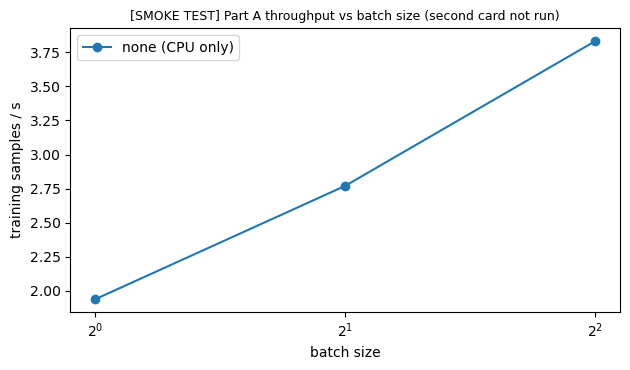

[SMOKE TEST] no CUDA memory stats on CPU, so the memory figures are skipped


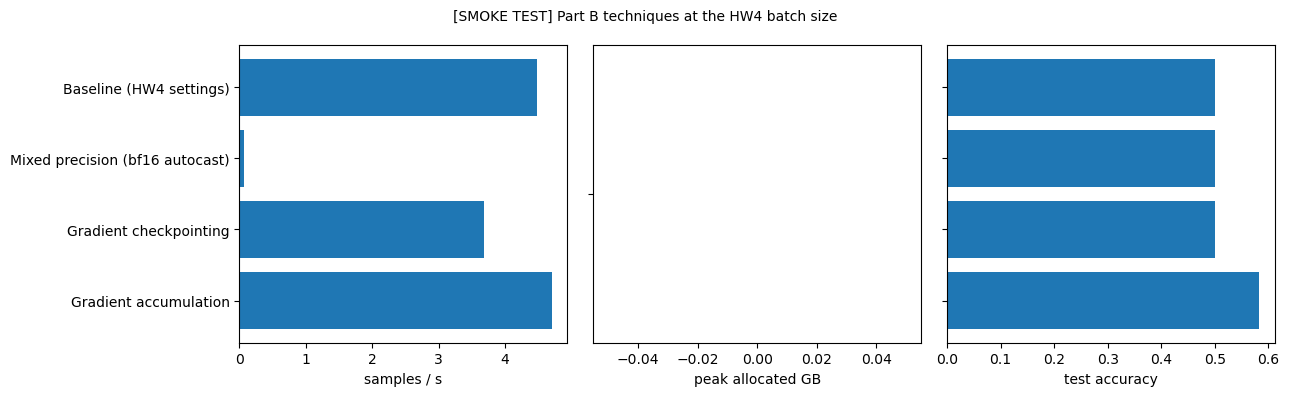

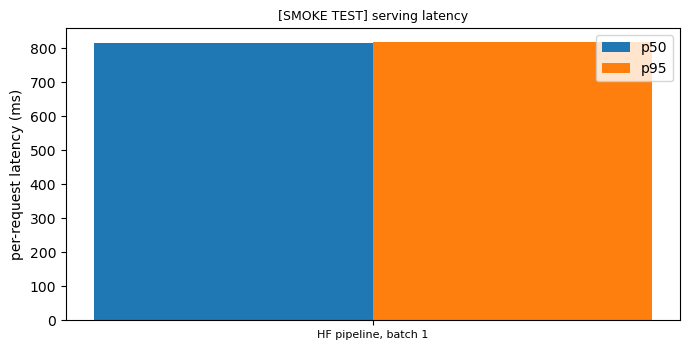

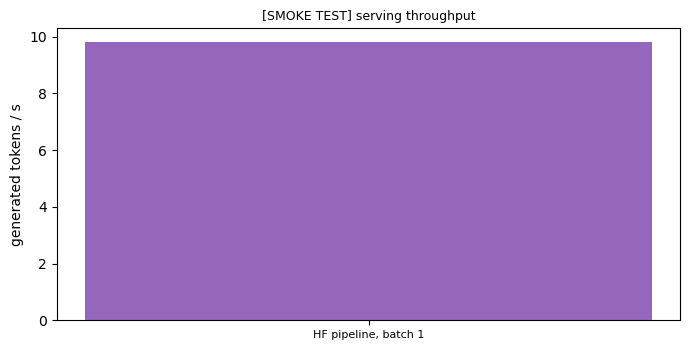

In [24]:
ok_a = part_a_df[part_a_df.status == "ok"]
fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.plot(ok_a.batch_size, ok_a.samples_per_s, marker="o", label=GPU_NAME)
ax.set_xscale("log", base=2); ax.set_xlabel("batch size"); ax.set_ylabel("training samples / s")
ax.set_title(f"{RUN_LABEL} Part A throughput vs batch size (second card not run)", fontsize=9); ax.legend()
fig.tight_layout(); fig.savefig(FIG_DIR / "batch_size_vs_throughput.png", dpi=150); plt.show()

if CUDA:
    fig, ax = plt.subplots(figsize=(6.4, 3.8))
    ax.plot(ok_a.batch_size, ok_a.peak_alloc_gb, marker="o", label="peak allocated")
    ax.plot(ok_a.batch_size, ok_a.peak_reserved_gb, marker="s", label="peak reserved")
    ax.axhline(ENV["gpu_vram_gb"], ls="--", c="gray", lw=1, label="total VRAM")
    ax.set_xscale("log", base=2); ax.set_xlabel("batch size"); ax.set_ylabel("GB")
    ax.set_title(f"{RUN_LABEL} Part A peak memory vs batch size", fontsize=9); ax.legend()
    fig.tight_layout(); fig.savefig(FIG_DIR / "batch_size_vs_memory.png", dpi=150); plt.show()
else:
    print("[SMOKE TEST] no CUDA memory stats on CPU, so the memory figures are skipped")

ok_b = part_b_df[part_b_df.status == "ok"]
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col, lab in zip(axes, ["samples_per_s", "peak_alloc_gb", "test_acc"], ["samples / s", "peak allocated GB", "test accuracy"]):
    ax.barh(ok_b.technique, ok_b[col]); ax.set_xlabel(lab); ax.invert_yaxis()
for ax in axes[1:]:
    ax.set_yticklabels([])
fig.suptitle(f"{RUN_LABEL} Part B techniques at the HW4 batch size", fontsize=10)
fig.tight_layout(); fig.savefig(FIG_DIR / "technique_comparison.png", dpi=150); plt.show()

x = np.arange(len(serve))
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(x - 0.2, serve.p50_ms, 0.4, label="p50"); ax.bar(x + 0.2, serve.p95_ms, 0.4, label="p95")
ax.set_xticks(x, serve.config, fontsize=8); ax.set_ylabel("per-request latency (ms)"); ax.legend()
ax.set_title(f"{RUN_LABEL} serving latency", fontsize=9)
fig.tight_layout(); fig.savefig(FIG_DIR / "serving_latency_comparison.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(x, serve.tokens_per_s, color="tab:purple")
ax.set_xticks(x, serve.config, fontsize=8); ax.set_ylabel("generated tokens / s")
ax.set_title(f"{RUN_LABEL} serving throughput", fontsize=9)
fig.tight_layout(); fig.savefig(FIG_DIR / "serving_throughput_comparison.png", dpi=150); plt.show()

if CUDA:
    ok_kv = kv_df[kv_df.status == "ok"]
    fig, ax = plt.subplots(figsize=(6.4, 3.8))
    ax.plot(ok_kv.context_len, ok_kv.peak_above_weights_gb, marker="o", label="measured peak above weights")
    ax.plot(ok_kv.context_len, ok_kv.kv_theory_gb, marker="s", ls="--", label="theoretical KV cache")
    ax.set_xscale("log", base=2); ax.set_xlabel("context length (tokens)"); ax.set_ylabel("GB")
    ax.set_title(f"{RUN_LABEL} KV-cache memory vs context, batch {KV_BATCH} (HF)", fontsize=9); ax.legend()
    fig.tight_layout(); fig.savefig(FIG_DIR / "kv_cache_memory_vs_context.png", dpi=150); plt.show()

## 17. Part E — Calculations

**GPU-hours for one full fine-tune** = wall-clock time of the baseline fine-tune (training plus per-epoch validation) ÷ 3600 × 1 GPU. This is one HW4 fine-tune: 4 epochs on 3,500 training rows.

I also show what training on the whole TweetEval train split (45,615 rows) would cost at the same measured throughput. It's labelled as an estimate because it was never actually run.

In [25]:
b = part_b_df.set_index("technique")
base = b.loc[BASE_CFG["name"]]
gpu_hours = base.wall_time_incl_eval_s / 3600
full_rows_est_h = EPOCHS * N_AVAILABLE / base.samples_per_s / 3600
print(f"One HW4 fine-tune (baseline): {base.wall_time_incl_eval_s:.1f} s / 3600 = {gpu_hours:.4f} GPU-hours "
      f"({EPOCHS} epochs x {len(train_ds)} rows, {base.samples_per_s:.1f} samples/s training)")
print(f"Estimate only, not run: {EPOCHS} epochs x {N_AVAILABLE} rows / {base.samples_per_s:.1f} samples/s / 3600 "
      f"= {full_rows_est_h:.3f} GPU-hours (training steps only)")

print(f"Baseline reproduces HW4.a? test acc {base.test_acc:.4f} vs HW4.a {HW4A_TRAINING['test_accuracy']:.4f}; "
      f"training {base.train_time_s:.1f}s vs HW4.a {HW4A_TRAINING['train_time_s']:.1f}s; "
      f"peak {base.peak_alloc_gb:.3f} GB vs HW4.a {HW4A_TRAINING['peak_allocated_gb']:.3f} GB")

ok = part_b_df[part_b_df.status == "ok"]
best_mem = ok.loc[ok.peak_alloc_gb.idxmin()] if ok.peak_alloc_gb.notna().any() else None
best_thr = ok.loc[ok.samples_per_s.idxmax()]
best_wall = ok.loc[ok.wall_time_incl_eval_s.idxmin()]
HW45_SUMMARY = {
    "run_label": RUN_LABEL, "gpu": GPU_NAME,
    "best_peak_memory": None if best_mem is None else {"technique": best_mem.technique, "peak_alloc_gb": best_mem.peak_alloc_gb, "test_acc": best_mem.test_acc},
    "best_throughput": {"technique": best_thr.technique, "samples_per_s": best_thr.samples_per_s, "test_acc": best_thr.test_acc},
    "best_wall_clock": {"technique": best_wall.technique, "wall_time_incl_eval_s": best_wall.wall_time_incl_eval_s, "test_acc": best_wall.test_acc},
    "gpu_hours_one_finetune": gpu_hours, "gpu_hours_full_tweeteval_estimate": full_rows_est_h,
    "part_a_max_batch": A_MAX_BATCH, "part_a_first_oom": A_FIRST_OOM, "part_a_plateau_batch": A_PLATEAU,
    "kv_max_context_bs8_hf": KV_MAX_OK, "vllm_status": VLLM_STATUS, "vllm_kv_pool": VLLM_KV,
    "part_c": PART_C["status"], "note": "HW4.5 summary only; not an HW5 baseline",
}
_ = (RESULTS_DIR / "hw45_summary.json").write_text(json.dumps(HW45_SUMMARY, indent=2, default=float))
print(json.dumps(HW45_SUMMARY, indent=2, default=float))

One HW4 fine-tune (baseline): 22.9 s / 3600 = 0.0064 GPU-hours (2 epochs x 48 rows, 4.5 samples/s training)
Estimate only, not run: 2 epochs x 45615 rows / 4.5 samples/s / 3600 = 5.659 GPU-hours (training steps only)
Baseline reproduces HW4.a? test acc 0.5000 vs HW4.a 0.5000; training 21.4s vs HW4.a 23.6s; peak nan GB vs HW4.a nan GB
{
  "run_label": "[SMOKE TEST]",
  "gpu": "none (CPU only)",
  "best_peak_memory": null,
  "best_throughput": {
    "technique": "Gradient accumulation",
    "samples_per_s": 4.6978375939153585,
    "test_acc": 0.5833333333333334
  },
  "best_wall_clock": {
    "technique": "Gradient accumulation",
    "wall_time_incl_eval_s": 21.95547120799893,
    "test_acc": 0.5833333333333334
  },
  "gpu_hours_one_finetune": 0.006372928553052285,
  "gpu_hours_full_tweeteval_estimate": 5.658622802358067,
  "part_a_max_batch": 4,
  "part_a_first_oom": null,
  "part_a_plateau_batch": 4,
  "kv_max_context_bs8_hf": 128,
  "vllm_status": "[SKIPPED IN SMOKE TEST] vLLM needs a

### Conclusions

Pending the RTX 4090 run. These will be written from the tables above, and they'll only use numbers this notebook actually measured.

- **Part A:** where throughput stops improving, and the largest batch that ran. The two-card comparison and the max-batch vs VRAM ratio question can't be answered with one card.
- **Part B:** how much gradient checkpointing slowed training, which technique I'd apply first, and which I wouldn't bother with on a large-memory card.
- **Part C:** skipped (optional).
- **Part D:** HF vs vLLM latency and throughput, the KV-cache growth, the longest context served at batch 8, and how this run compares with HW4.a.
- **Part E:** the configuration I'd use for a full fine-tune, and the best peak-memory, throughput and wall-clock configurations. These are the HW4.5 summary only, not an HW5 baseline.

## 18. Final reproducibility checklist

In [26]:
checks = {
    "same data as HW4.a (sha256)": DATA_SHA256 == SAVED_SPLIT["data_sha256"],
    "same split as HW4.a": True,   # asserted in section 7
    "gradient checkpointing gives the same gradients": max_diff < 1e-4,
    "p50 <= p95 for every serving config": bool((serve.p50_ms <= serve.p95_ms).all()),
    "tokens/s and requests/s reported separately": {"tokens_per_s", "requests_per_s"} <= set(serve.columns),
    "Part A raw results saved": (RESULTS_DIR / "part_a_batch_scaling.csv").exists(),
    "Part B raw results saved": (RESULTS_DIR / "part_b_techniques.csv").exists(),
    "KV raw results saved": (RESULTS_DIR / "kv_cache_vs_context.csv").exists(),
    "tables written from saved files": (RESULTS_DIR / "hw45_tables.md").exists(),
}
for k, v in checks.items():
    print(("OK      " if v else "FAILED  ") + k)
print(f"vLLM: {VLLM_STATUS}\nPart C: {PART_C['status']}\n8-bit optimizer: {BNB_STATUS}")
assert all(checks.values())
ENV["end_utc"] = now_utc()
_ = (RESULTS_DIR / "env_hw45.json").write_text(json.dumps(ENV, indent=2))
log("HW4.5 notebook completed")

OK      same data as HW4.a (sha256)
OK      same split as HW4.a
OK      gradient checkpointing gives the same gradients
OK      p50 <= p95 for every serving config
OK      tokens/s and requests/s reported separately
OK      Part A raw results saved
OK      Part B raw results saved
OK      KV raw results saved
OK      tables written from saved files
vLLM: [SKIPPED IN SMOKE TEST] vLLM needs a CUDA GPU; it only runs with RUN_MODE='gpu' on the RTX 4090
Part C: Part C skipped (optional)
8-bit optimizer: [DEPENDENCY ERROR] ModuleNotFoundError: No module named 'bitsandbytes'
2026-10-27T00:51:00Z [SMOKE TEST] HW4.5 notebook completed


## 19. Download all outputs

Zips the results, figures, provenance files and checkpoint configs from both notebooks and downloads the zip. In Colab it downloads straight away; in plain Jupyter or VS Code it shows a link. If the checklist above stops on a failed check, this cell can still be run on its own.

In [ ]:
import zipfile

# One zip with everything both notebooks produced in this mode: results (CSV, JSON, tables, run logs),
# figures, provenance (nvidia-smi captures) and the checkpoint config/tokenizer files.
# Model weights (~440 MB) are left out, the same as in .gitignore.
ZIP_PATH = HW_DIR / f"HW4.5_{RUN_MODE}_outputs.zip"
folders = [HW_DIR / "results" / RUN_MODE, HW_DIR / "figures" / RUN_MODE, PROV_DIR, HW_DIR / "checkpoints" / RUN_MODE]
extra = [HW_DIR / "results" / "hw4a_split.json"]
files = [f for d in folders if d.exists() for f in sorted(d.rglob("*")) if f.is_file()] + [f for f in extra if f.exists()]
files = [f for f in files if f.suffix not in (".safetensors", ".bin", ".zip")]
with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as z:
    for f in files:
        z.write(f, f.relative_to(HW_DIR))
print(f"{ZIP_PATH.name}: {len(files)} files, {ZIP_PATH.stat().st_size / 1e6:.1f} MB")

try:
    from google.colab import files as colab_files   # Colab, including a local Docker runtime
    colab_files.download(str(ZIP_PATH))
except ImportError:
    from IPython.display import FileLink, display     # plain Jupyter / VS Code
    display(FileLink(ZIP_PATH.relative_to(HW_DIR)))